# Compara cinco modelos cinéticos de flotación con la misma evidencia

**Pregunta:** ¿Cómo se compara el error de ajuste de cada modelo cinético publicado con su error de proyección al banco continuo?

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema. Tiempo de lectura: 24 minutos.

## Objetivos

Compara cinco formas cinéticas citadas sobre la misma evidencia batch y evalúa por separado la proyección de banco frente a la referencia exacta con tasas distribuidas del motor.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 3 sobre 02-flotation, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/cases/copper_molybdenum.json`, escenario de autoría propia bajo licencia MIT del proyecto. Observaciones y referencia exacta las genera el modelo, no son datos de planta medidos. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Las formas candidatas son primer orden, Kelsall rápida/lenta, Klimpel de tasas uniformes, gamma y exponencial estirada. Cada una resume de modo distinto tasas heterogéneas. OreFlow evalúa la misma curva batch virtual y compara proyecciones de banco; una curva ajustada no identifica un mecanismo único.

## Comparación

La cinética de primer orden (Kelsall (1961) es una referencia clásica de fracción rápida/lenta. Kelsall y las formas de tasas distribuidas representan mejor la heterogeneidad con más parámetros. OreFlow implementa cinco formas en `pipeline/engine/kinetics.py` y mide tanto error batch como error de proyección frente a su distribución exacta de tasas. Es una comparación controlada, no superioridad demostrada con datos de planta ni un algoritmo nuevo.

Carga un registro cinético comprometido para que todos los modelos usen las mismas observaciones y predicciones.

In [2]:
# Carga un registro cinético comprometido para que todos los modelos usen las mismas observaciones y
# predicciones.
case_record = json.loads(
    (repo / "data/derived/cases/copper_molybdenum.json").read_text(encoding="utf-8")
)
kinetics = case_record["variants"][0]["trace"]["methods"]["kinetics"]
models = kinetics["models"]
print("status:", kinetics["status"], "| payable:", kinetics["species"])
print("bank residence (min):", kinetics["bank"]["residence_min"])
print("exact bank recuperación (%):", kinetics["bank"]["exact_true_flotation_pct"])


status: computed | payable: Cu
bank residence (min): 29.161577021309544
exact bank recuperación (%): 93.9822410776771


Compara en paralelo el ajuste batch y error de banco; sus ordenamientos pueden diferir.

In [3]:
# Compara en paralelo el ajuste batch y error de banco; sus ordenamientos pueden diferir.
scores = pd.DataFrame(
    [
        {
            "model": m["id"],
            "batch RMSE (puntos)": m["rmse_pct"],
            "Predicción del banco (%)": m["bank_projection_pct"],
            "Error de banco (puntos)": m["lumping_error_pct"],
            "Brecha de extrapolación (puntos)": m["ultimate_gap_pct"],
        }
        for m in models
    ]
)
display(scores.set_index("model").round(3).sort_values("batch RMSE (puntos)"))


,batch RMSE (puntos),Predicción del banco (%),Error de banco (puntos),Brecha de extrapolación (puntos)
model,,,,
kelsall,0.028,92.662,-1.320,4.540
gamma,0.146,92.951,-1.032,7.034
klimpel,0.398,92.665,-1.318,9.604
stretched_exponential,0.667,90.005,-3.977,1.724
first_order,1.640,87.393,-6.590,0.471


Grafica los modelos ajustados sobre las mismas observaciones batch. La figura siguiente compara sus proyecciones de banco con la referencia exacta del motor.

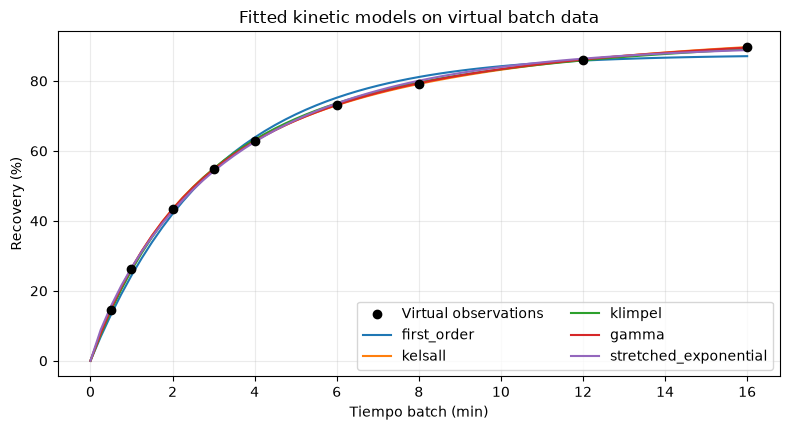

In [4]:
# Grafica los modelos ajustados sobre las mismas observaciones batch.
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(
    kinetics["times_min"],
    kinetics["batch_recovery_pct"],
    color="black",
    zorder=4,
    label="Virtual observations",
)
for m in models:
    ax.plot(kinetics["dense_times_min"], m["dense_pct"], label=m["id"])
ax.set(
    xlabel="Tiempo batch (min)",
    ylabel="Recovery (%)",
    title="Fitted kinetic models on virtual batch data",
)
ax.grid(True, alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()


La figura 14 de nivel 3 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 14 de nivel 3 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 14 de nivel 3 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 14 solo guía la comparación.

Compara las proyecciones de banco con el resultado exacto de tasas distribuidas. Un buen ajuste batch no garantiza una buena proyección por la distribución continua de residencia.

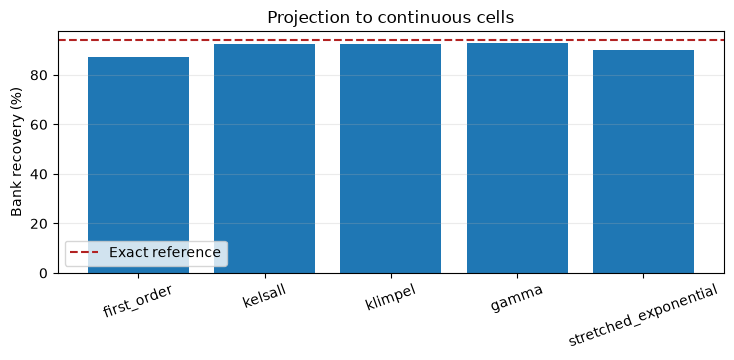

In [5]:
# Compara las proyecciones de banco con el resultado exacto de tasas distribuidas.
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.bar([m["id"] for m in models], [m["bank_projection_pct"] for m in models])
ax.axhline(
    kinetics["bank"]["exact_true_flotation_pct"],
    color="firebrick",
    linestyle="--",
    label="Exact reference",
)
ax.set(ylabel="Bank recovery (%)", title="Projection to continuous cells")
ax.tick_params(axis="x", rotation=20)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()


La figura 16 de nivel 3 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 16 de nivel 3 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 16 de nivel 3 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 16 solo guía la comparación.

En el caso de nivel 3 sobre 02 flotation, la corrida con 0.8× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 02 flotation, con 0.8× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 512.0
recovery (%): 94.842
product P80 (µm): 150.0


En el caso de nivel 3 sobre 02 flotation, la corrida con 0.9× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 02 flotation, con 0.9× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 94.143
product P80 (µm): 150.0


En el caso de nivel 3 sobre 02 flotation, la corrida con 1.0× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 02 flotation, con 1.0× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 640.0
recovery (%): 93.447
product P80 (µm): 150.0


Ajusta las formas cinéticas citadas a la respuesta batch virtual y proyecta cada ajuste por la distribución de residencia del banco rougher resuelto. Se usa el procedimiento de ajuste publicado de OreFlow; la entrada sigue siendo un caso generado por el modelo.

In [9]:
# Fit and project the implemented flotation kinetic models.
from pipeline.engine.kinetics import kinetic_record

kinetic = kinetic_record(
    response_1_0.flotation,
    response_1_0.ore,
    case.nominal.rougher_cells,
    response_1_0.metrics["rougher_recovery_pct"],
)
print("kinetic model fits:", len(kinetic["models"]))
print(
    "exact true-flotation bank recovery (%):", round(kinetic["bank"]["exact_true_flotation_pct"], 3)
)


kinetic model fits: 5
exact true-flotation bank recovery (%): 93.982


En el caso de nivel 3 sobre 02 flotation, la corrida con 1.1× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 02 flotation, con 1.1× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 704.0
recovery (%): 92.753
product P80 (µm): 150.0


En el caso de nivel 3 sobre 02 flotation, la corrida con 1.2× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 3 sobre 02 flotation, con 1.2× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [11]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 768.0
recovery (%): 89.749
product P80 (µm): 167.43


En la lección de nivel 3 sobre 02 flotation, la lectura del gráfico 1 considera en esta figura del nivel 3 sobre 02 flotation, compara la recuperación con el P80 de producto al variar el tratamiento. En la lección de nivel 3 sobre 02 flotation, la lectura del gráfico 2 considera los ejes separan unidades distintas, así que el cambio describe el caso de autoría propia y no una tendencia empírica de planta. En la lección de nivel 3 sobre 02 flotation, la lectura del gráfico 3 considera el punto nominal sirve como referencia para los ajustes vecinos. En la lección de nivel 3 sobre 02 flotation, la lectura del gráfico 4 considera en «Compara cinco modelos cinéticos de flotación con la misma evidencia», cada punto procede de una evaluación independiente del motor y las líneas solo guían la vista entre ajustes probados.

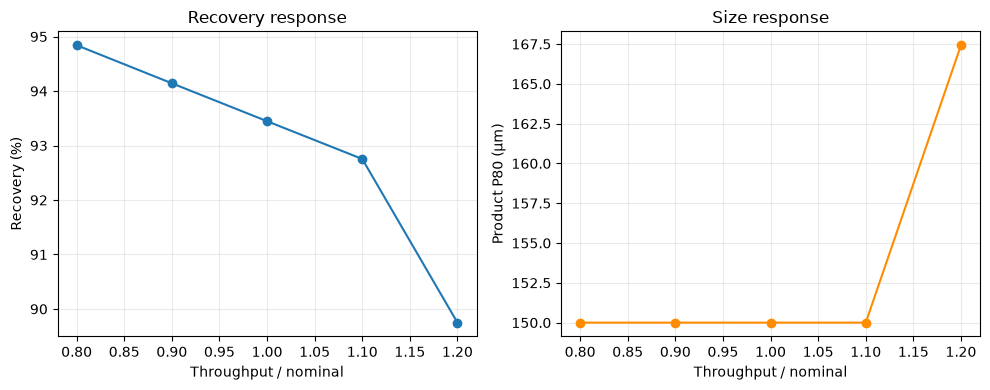

In [12]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


La figura 30 de nivel 3 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 30 de nivel 3 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 30 de nivel 3 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 30 solo guía la comparación.

En el nivel 3 de 02 flotation, la interpretación 1 es que la recuperación por flotación depende de los sólidos y minerales que entrega la molienda, los parámetros declarados de flotabilidad, la respuesta al colector y el tiempo de residencia disponible. En el nivel 3 de 02 flotation, la interpretación 2 es que un mayor tratamiento reduce el tiempo disponible por unidad de masa si el volumen de celdas no cambia. En el nivel 3 de 02 flotation, la interpretación 3 es que el modelo representa ese acoplamiento en el cálculo del banco. En el nivel 3 de 02 flotation, la interpretación 4 es que no anima partículas individuales ni infiere comportamiento de espuma desde una imagen. En el nivel 3 de 02 flotation, la interpretación 5 es que compara recuperación del mineral valioso con ley de concentrado y recuperación de agua, porque una mejora de recuperación también puede arrastrar más ganga o agua. En el nivel 3 de 02 flotation, la interpretación 6 es que formas cinéticas de primer orden, fracción rápida/lenta y tasas distribuidas pueden ajustar curvas batch similares y producir proyecciones distintas del banco. En el nivel 3 de 02 flotation, la interpretación 7 es que una referencia sintética de tasas exactas permite medir error de aproximación interno, pero no es un ensayo de laboratorio. En el nivel 3 de 02 flotation, la interpretación 8 es que transferir a una planta requiere muestras temporizadas, registros de reactivos, aire, geometría de celdas y una campaña independiente reservada. En el nivel 3 de 02 flotation, la extensión 1 muestra que una comparación cinética defendible mantiene fijos tiempos batch, recuperación última ajustada y supuestos de residencia del banco entre formas candidatas. En el nivel 3 de 02 flotation, la extensión 2 muestra que informa la estructura de residuos además del RMSE, porque muestras tardías pueden dominar un ajuste cuadrático mientras la recuperación temprana controla un banco corto. En el nivel 3 de 02 flotation, la extensión 3 muestra que no interpretes los parámetros ajustados como constantes minerales únicas cuando el mismo simulador genera las observaciones.

## Resultados

**Respuesta:** En esta lección de nivel 3 sobre 02 flotation, el circuito ejecutado informa una recuperación de 93.9822410776771 por ciento para «Compara cinco modelos cinéticos de flotación con la misma evidencia» en el primer tratamiento controlado.

La primera figura compara ajustes sobre los mismos datos virtuales; la segunda compara proyecciones con el modelo exacto de tasas distribuidas. Miden error de aproximación dentro del motor OreFlow, no precisión en el mundo real. Ajuste batch y proyección de banco responden preguntas diferentes.

## Resumen

La comparación bibliográfica muestra tanto la capacidad como el límite: varias formas clásicas ajustan una curva sintética, pero sus predicciones de banco divergen. OreFlow informa la diferencia en vez de presentar la animación como dinámica de planta.

## Referencias

- https://doi.org/10.1016/S0301-7516(99)00069-1
- https://doi.org/10.5277/ppmp170128
- https://doi.org/10.1016/j.mineng.2025.109246
- https://doi.org/10.1016/0301-7516(81)90019-3